In [1]:
import polars as pl
import matplotlib.pyplot as plt

## Load branchwater results w/pvals, filter at 1e-6, and add metag & species columns

In [2]:
bw_df = (
    pl.scan_parquet('outputs.branchwater/csv+pvals/*.parquet')
    .filter(pl.col('pval') < 1e-6)
    .with_columns(
        metag=pl.col('match_name'),
        species=pl.col('query_name').str.split(' ').list.slice(1, 2).list.join(' '),
    )
    .select(['metag', 'species', 'intersect_hashes', 'pval'])
).collect()
bw_df

metag,species,intersect_hashes,pval
str,str,i64,f64
"""SRR13206894""","""s__13-2-20CM-66-19 sp021838635""",833,0.0
"""SRR13178631""","""s__13-2-20CM-66-19 sp021838635""",830,0.0
"""SRR13213328""","""s__13-2-20CM-66-19 sp021838635""",830,0.0
"""SRR13170410""","""s__13-2-20CM-66-19 sp021838635""",829,0.0
"""SRR13170413""","""s__13-2-20CM-66-19 sp021838635""",828,0.0
…,…,…,…
"""SRR5216647""","""s__Rhizomicrobium sp021851325""",8,1.0373e-10
"""SRR12678630""","""s__Rhizomicrobium sp021851325""",7,2.1618e-8
"""DRR014257""","""s__Rhizomicrobium sp021851325""",6,4.9296e-8


## Remove already searched accessions (about ~100)

In [3]:
already_searched_accs = set([ x.strip() for x in open('/home/hehouts/AMD/sra_accessions_AMD.txt') ])
bw_rm_df = bw_df.filter(~(pl.col('metag').is_in(already_searched_accs)))
print(len(bw_df), len(bw_rm_df))

75924 74385


## Group by metagenomes and calculate num species per metag; sort by that.

In [4]:
num_acc = bw_df['metag'].n_unique()
by_acc = bw_df.group_by('metag').agg(
    num_species=pl.len()
).sort('num_species', descending=True).with_row_index('acc_id')

In [5]:
by_acc

acc_id,metag,num_species
u32,str,u32
0,"""SRR17201078""",18
1,"""SRR13221996""",17
2,"""SRR13170414""",17
3,"""SRR25885109""",17
4,"""SRR13300764""",17
…,…,…
33234,"""SRR8416121""",1
33235,"""ERR10482437""",1
33236,"""ERR868346""",1


## Plot decay curve, ordered by rank

(0.0, 2000.0)

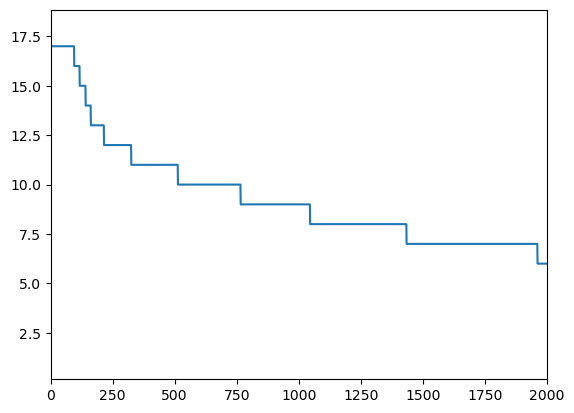

In [6]:
plt.plot(by_acc['acc_id'], by_acc['num_species'])
plt.xlim(0, 2000)

## Load in SRA metadata

In [7]:
metadata_df = pl.read_parquet("/group/ctbrowngrp5/sra-metagenomes/20241128-metadata.parquet")

## Join metadata into search results table

In [8]:
join_df = by_acc.join(metadata_df, left_on='metag', right_on='acc', how='inner')
join_df

acc_id,metag,num_species,sample_name,sample_name_sam,assay_type,avgspotlen,bioproject,biosample,biosamplemodel_sam,center_name,collection_date_sam,consent,datastore_filetype,datastore_provider,datastore_region,ena_first_public_run,ena_last_update_run,experiment,geo_loc_name_country_calc,geo_loc_name_country_continent_calc,geo_loc_name_sam,insertsize,instrument,library_name,librarylayout,libraryselection,librarysource,loaddate,mbases,mbytes,organism,platform,releasedate,sample_acc,sra_study,age,altitude,body_habitat,body_product,collection_date,depth,env_biome,env_broad_scale,env_feature,env_local_scale,env_material,env_medium,env_package,host,host_age,host_body_habitat,host_body_product,host_common_name,host_sex,host_subject_id,host_taxid,investigation_type,isolate,lat_lon,project_name,race,sample_type,source_material_id,bases,bytes,run_file_create_date,run_file_version,primary_search
u32,str,u32,str,list[str],str,i64,str,str,list[str],str,date,str,list[str],list[str],list[str],list[str],list[str],str,str,str,list[str],i64,str,str,str,str,str,"datetime[μs, UTC]",i64,i64,str,str,"datetime[μs, UTC]",str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
16067,"""SRR27292737""",1,"""D1-5""",[],"""WGS""",300,"""PRJNA1054761""","""SAMN38918210""","[""Microbe, viral or environmental""]","""CHENGDU UNIVERSITY OF TRADITIO…",2022-12-01,"""public""","[""fastq"", ""run.zq"", ""sra""]","[""gs"", ""ncbi"", ""s3""]","[""gs.us-east1"", ""ncbi.public"", ""s3.us-east-1""]",[],[],"""SRX22970389""","""China""","""Asia""","[""China:Chengdu""]",null,"""DNBSEQ-G400""","""D1-5""","""PAIRED""","""RANDOM""","""METAGENOMIC""",null,293,84,"""Plesiomonas shigelloides""","""DNBSEQ""",2024-03-15 00:00:00 UTC,"""SRS19951405""","""SRP479064""",null,null,null,null,"""[""2022-12""]""",null,null,"""[""not collected""]""",null,"""[""not collected""]""",null,"""[""not collected""]""",null,"""[""Danio rerio""]""",null,null,null,null,null,null,null,null,null,"""""not collected""""",null,null,null,null,"""293209500""","""88137695""","""""2023-12-20T01:35:00.000Z""""",null,"""""1054761"""""
14886,"""ERR3360142""",2,"""SAMEA5282610""","[""033""]","""WGS""",149,"""PRJEB31019""","""SAMEA5282610""",[],"""UNIVERSITY OF EAST ANGLIA, UK""",null,"""public""","[""fastq"", ""run.zq"", ""sra""]","[""ena"", ""gs"", … ""s3""]","[""ena"", ""gs.us-east1"", … ""s3.us-east-1""]","[""2019-06-07""]","[""2019-10-12""]","""ERX3384434""",null,null,[],null,"""unspecified""","""Synthetic""","""PAIRED""","""other""","""METAGENOMIC""",null,89997,49361,"""synthetic metagenome""","""ILLUMINA""",2019-06-10 00:00:00 UTC,"""ERS3089878""","""ERP113526""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""89997553387""","""51759745548""","""""2019-06-14T16:07:00.000Z""""",null,"""""033"""""
8951,"""SRR10686760""",2,"""HH20""",[],"""WGS""",300,"""PRJNA594760""","""SAMN13552547""","[""Metagenome or environmental""]","""OIL CROPS RESEARCH INSTITUTE O…",null,"""public""","[""fastq"", ""run.zq"", ""sra""]","[""gs"", ""ncbi"", ""s3""]","[""gs.us-east1"", ""ncbi.public"", ""s3.us-east-1""]",[],[],"""SRX7363690""","""China""","""Asia""","[""China:hong'an""]",null,"""Illumina HiSeq 2000""","""HH20 (metagenome)""","""PAIRED""","""PCR""","""METAGENOMIC""",null,10278,4410,"""plant metagenome""","""ILLUMINA""",2019-12-14 00:00:00 UTC,"""SRS5822682""","""SRP237458""",null,null,null,null,"""[""2016""]""",null,null,null,null,null,null,null,null,"""[""peanut""]""",null,null,null,null,null,null,null,null,null,"""""30.9612 N 114.6454 E""""",null,null,null,null,"""10278007800""","""4624922293""","""""2019-12-13T23:58:00.000Z""""",null,"""""13552547"""""
7121,"""ERR4691764""",3,"""SAMEA2731264""","[""TARA_N000000459""]","""WGS""",198,"""PRJEB4352""","""SAMEA2731264""",[],"""GSC""",null,"""public""","[""fastq"", ""run.zq"", ""sra""]","[""gs"", ""n

## Filter at 10 or more species matches

In [9]:
join2_df = join_df.filter(pl.col('num_species') >= 10)

## Display environment foo

In [10]:
join2_df['organism'].value_counts(sort=True).filter(pl.col('count') > 10).style

organism,count
soil metagenome,360
mine drainage metagenome,107
rhizosphere metagenome,86
wetland metagenome,34
root metagenome,28
mine tailings metagenome,27
metagenome,20
wastewater metagenome,19
uncultured bacterium,15
peat metagenome,14


## How many bioprojects we talking 'bout?

In [11]:
join2_df['bioproject'].value_counts(sort=True).head(10)

bioproject,count
str,u32
"""PRJNA666025""",91
"""PRJNA450295""",25
"""PRJNA1012134""",20
"""PRJNA1128034""",19
"""PRJNA779554""",13
"""PRJEB31441""",12
"""PRJNA785287""",12
"""PRJNA776090""",11
"""PRJNA1109856""",10


In [12]:
mancur_descriptions = {
    'PRJNA666025': 'acid mine drainage sediment metagenome Raw sequence reads ',
    'PRJNA450295': 'This project is focusing on deciphering the functional complexity of foxtail millet root microbiota using ultra-deep metagenomic sequencing and identifying biomarkers for millet yield.',
    'PRJNA1012134': 'acidic copper mine tailings soil metagenome',
    'PRJNA1128034': 'Genomic DNA was extracted from five replicate rhizosphere soil samples of two tall (Chidham White Chaff and Red Lammas) and two semi-dwarf (Mallacca and Gallant) wheat cultivars, and three replicate bulk soil samples, to investigate prokaryote community taxonomy and function by shotgun metagenomics.',
    'PRJNA779554': 'In this research, we aimed at doing a metagenome analysis of rhizosphere soil.',
    'PRJEB31441': 'Due to little organic matter and poor nutrition contents, phytostabilization of the extremely acidic mine tailings remains a great change. Microorganisms play an important role in carbon, nitrogen and phosphorous cycling, which might help the necessary element recycling during practical phytostabilization process. Therefore, we analyzed the role of microbes in carbon fixation and nutrient release in an acidic mine tailings before and after direct revegetation for 3 and 4 years by metagenomic sequencing.',
    'PRJNA785287': 'Microbial community from Acid Mine Drainage passive treatment ',
    'PRJNA776090': 'Mult-omics Data of Citrus Reticulata Chachi ',
    'PRJNA1109856': 'The study aimed to understand the changes in community composition and factors responsible for bacterial community reconstruction after a prescribed burn. Samples were sequenced from burned and unburned plots one week and five months after the prescribed burn.',
    'PRJNA781406': 'Investigating the microbiomes associated to glacier-fed streams around the world',
}

# convert to DataFrame
xx = []
for k, v in mancur_descriptions.items():
    xx.append(dict(bioproject=k,
                  descr=v))

mancur_df = pl.DataFrame(xx)

In [13]:
join2_df['bioproject'].value_counts(sort=True).join(mancur_df, on='bioproject', how='left').head(15).style

bioproject,count,descr
PRJNA666025,91,acid mine drainage sediment metagenome Raw sequence reads
PRJNA450295,25,This project is focusing on deciphering the functional complexity of foxtail millet root microbiota using ultra-deep metagenomic sequencing and identifying biomarkers for millet yield.
PRJNA1012134,20,acidic copper mine tailings soil metagenome
PRJNA1128034,19,"Genomic DNA was extracted from five replicate rhizosphere soil samples of two tall (Chidham White Chaff and Red Lammas) and two semi-dwarf (Mallacca and Gallant) wheat cultivars, and three replicate bulk soil samples, to investigate prokaryote community taxonomy and function by shotgun metagenomics."
PRJNA779554,13,"In this research, we aimed at doing a metagenome analysis of rhizosphere soil."
PRJEB31441,12,"Due to little organic matter and poor nutrition contents, phytostabilization of the extremely acidic mine tailings remains a great change. Microorganisms play an important role in carbon, nitrogen and phosphorous cycling, which might help the necessary element recycling during practical phytostabilization process. Therefore, we analyzed the role of microbes in carbon fixation and nutrient release in an acidic mine tailings before and after direct revegetation for 3 and 4 years by metagenomic sequencing."
PRJNA785287,12,Microbial community from Acid Mine Drainage passive treatment
PRJNA776090,11,Mult-omics Data of Citrus Reticulata Chachi
PRJNA1109856,10,The study aimed to understand the changes in community composition and factors responsible for bacterial community reconstruction after a prescribed burn. Samples were sequenced from burned and unburned plots one week and five months after the prescribed burn.
PRJNA781406,9,Investigating the microbiomes associated to glacier-fed streams around the world
